In [14]:
# Import required library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Question 1: Load a CSV File Using Pandas and Display Basic Information

In [2]:
# Load the dataset
df = pd.read_csv("SQL_Sales_Dataset.csv")

# Display first five records
df.head()

,order_id,customer_name,order_date,category,sub_category,product_name,quantity,unit_price,total_price,region
0,1000,Caleb Davis,2025-01-31,Clothing,Jeans,Jeans Try,2,1197,2394,West
1,1001,Misty Herrera,2025-05-05,Clothing,Jeans,Jeans New,9,1509,13581,South
2,1002,Rick Soto,2025-06-09,Clothing,Shoes,Shoes Us,5,1046,5230,East
3,1003,Sean Haas,2025-02-27,Furniture,Desk,Desk Section,10,292,2920,South
4,1004,Ann Hall,2025-06-01,Furniture,Cabinet,Cabinet Center,2,548,1096,North


In [3]:
# Display dataset dimensions
print("Number of Rows and Columns:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()

# Display statistical summary
print("\nStatistical Summary:")
df.describe()

Number of Rows and Columns: (200, 10)

Column Names:
['order_id', 'customer_name', 'order_date', 'category', 'sub_category', 'product_name', 'quantity', 'unit_price', 'total_price', 'region']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   order_id       200 non-null    int64 
 1   customer_name  200 non-null    object
 2   order_date     200 non-null    object
 3   category       200 non-null    object
 4   sub_category   200 non-null    object
 5   product_name   200 non-null    object
 6   quantity       200 non-null    int64 
 7   unit_price     200 non-null    int64 
 8   total_price    200 non-null    int64 
 9   region         200 non-null    object
dtypes: int64(4), object(6)
memory usage: 15.8+ KB

Statistical Summary:


,order_id,quantity,unit_price,total_price
count,200.000000,200.000000,200.000000,200.000000
mean,1099.500000,4.910000,2421.495000,12100.535000
std,57.879185,3.017853,1464.016187,10915.548067
min,1000.000000,1.000000,79.000000,79.000000
25%,1049.750000,2.000000,1120.000000,3060.000000
50%,1099.500000,5.000000,2373.500000,8912.000000
75%,1149.250000,7.000000,3541.750000,19350.750000
max,1199.000000,10.000000,4997.000000,47940.000000


## Question 2: Handle Missing Values and Duplicates Using Pandas

In [15]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Calculate total missing values
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
order_id         0
customer_name    0
order_date       0
category         0
sub_category     0
product_name     0
quantity         0
unit_price       0
total_price      0
region           0
dtype: int64

Total Missing Values:
0


In [5]:
# Count duplicate records
print("Total Duplicate Records:", df.duplicated().sum())

Total Duplicate Records: 0


In [7]:
# Create a copy of the original dataset
df_cleaned = df.copy()

# Remove duplicate records
df_cleaned = df_cleaned.drop_duplicates()

# Handle missing values
df_cleaned = df_cleaned.dropna()

# Display final dataset information
print("Dataset Shape Before Cleaning:", df.shape)
print("Dataset Shape After Cleaning:", df_cleaned.shape)

print("\nMissing Values After Cleaning:")
print(df_cleaned.isnull().sum())

print("\nDuplicate Records After Cleaning:")
print(df_cleaned.duplicated().sum())

Dataset Shape Before Cleaning: (200, 10)
Dataset Shape After Cleaning: (200, 10)

Missing Values After Cleaning:
order_id         0
customer_name    0
order_date       0
category         0
sub_category     0
product_name     0
quantity         0
unit_price       0
total_price      0
region           0
dtype: int64

Duplicate Records After Cleaning:
0


## Question 3: Group Data by Category and Find Total Revenue

In [13]:
# Calculate total revenue for each category
category_revenue = df_cleaned.groupby('category')['total_price'].sum()

# Display category-wise revenue
print("Total Revenue by Category:")
print(category_revenue)

# Display results in descending order
print("\nCategories Sorted by Revenue:")
print(category_revenue.sort_values(ascending=False))

Total Revenue by Category:
category
Clothing       484259
Electronics    549302
Furniture      714399
Grocery        672147
Name: total_price, dtype: int64

Categories Sorted by Revenue:
category
Furniture      714399
Grocery        672147
Electronics    549302
Clothing       484259
Name: total_price, dtype: int64


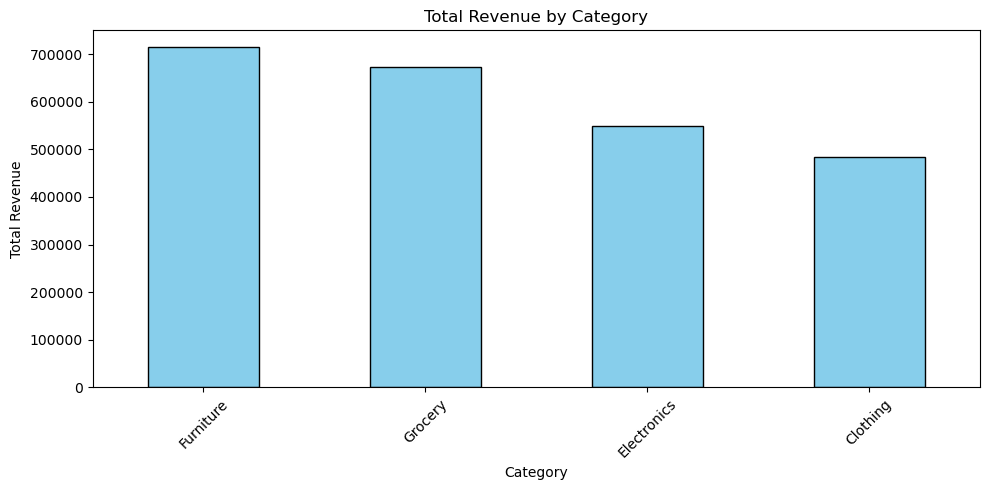

In [12]:
# Visualize category-wise revenue
plt.figure(figsize=(10, 5))

category_revenue.sort_values(ascending=False).plot(
    kind='bar',
    color='skyblue',
    edgecolor='black'
)

plt.title('Total Revenue by Category')
plt.xlabel('Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Observation

The analysis shows the total revenue generated by each product category. Furniture generates the highest revenue, while Clothing generates the lowest revenue. This analysis helps identify the best-performing product categories.

## Question 4: Sort Data by Multiple Columns Using Python

In [17]:
# Sort data by multiple columns
sorted_data = df_cleaned.sort_values(
    by=['category', 'total_price'],
    ascending=[True, False]
)

# Display sorted dataset
print("Dataset Sorted by Category and Total Price:")
display(sorted_data.head(10))

Dataset Sorted by Category and Total Price:


,order_id,customer_name,order_date,category,sub_category,product_name,quantity,unit_price,total_price,region
168,1168,Megan Charles,2025-03-26,Clothing,Jeans,Jeans Card,10,4462,44620,West
59,1059,Miss Rebecca Levine,2025-02-28,Clothing,Shirt,Shirt Look,6,4794,28764,East
157,1157,Patricia Gill,2025-03-23,Clothing,Jacket,Jacket Song,7,3915,27405,East
180,1180,Hailey Cobb,2025-02-19,Clothing,Jacket,Jacket Heart,6,4285,25710,East
82,1082,Kenneth Lee,2025-05-06,Clothing,Jacket,Jacket Realize,7,3486,24402,West
42,1042,David Norris,2025-06-10,Clothing,Shoes,Shoes Far,7,3445,24115,South
171,1171,David Dominguez,2025-03-06,Clothing,Shoes,Shoes Each,8,2902,23216,South
128,1128,Gregory Miller,2025-02-21,Clothing,Jacket,Jacket Image,8,2822,22576,South
62,1062,Jessica Hernandez,2025-05-21,Clothing,Shoes,Shoes Care,7,3208,22456,East
99,1099,Amanda Reeves,2025-04-21,Clothing,Jeans,Jeans Family,5,4419,22095,South


### Observation

The dataset was successfully sorted using multiple columns. Categories were arranged in ascending order, while total prices were arranged in descending order within each category. This helps identify high-value transactions in each product category.

## Question 5: Create a Correlation Matrix for Numerical Columns

In [18]:
# Select numerical columns
numerical_data = df_cleaned.select_dtypes(include=['number'])

# Calculate correlation matrix
correlation_matrix = numerical_data.corr()

# Display correlation matrix
print("Correlation Matrix:")
display(correlation_matrix)

Correlation Matrix:


,order_id,quantity,unit_price,total_price
order_id,1.000000,-0.018182,0.102267,0.099480
quantity,-0.018182,1.000000,0.047996,0.655212
unit_price,0.102267,0.047996,1.000000,0.671318
total_price,0.099480,0.655212,0.671318,1.000000


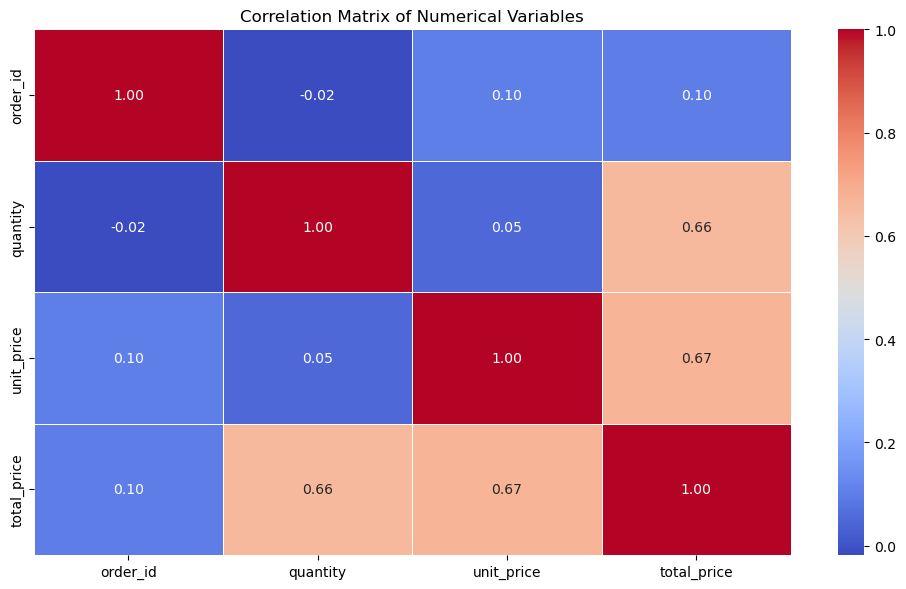

In [19]:
# Visualize correlation matrix using heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix of Numerical Variables')
plt.tight_layout()
plt.show()

### Observation

The correlation matrix helps understand the relationships between numerical variables. Positive correlation indicates that two variables tend to increase together, while negative correlation indicates an opposite relationship. Values closer to zero indicate a weaker linear relationship.

# Conclusion

In this internship task, I performed data analysis using Python and Pandas on the provided SQL Sales Dataset.

The analysis included loading and exploring the dataset, handling missing values and duplicates, calculating category-wise revenue, sorting records using multiple columns, and creating a correlation matrix.

These operations helped me understand data cleaning, data manipulation, and exploratory data analysis using Python.